Étape 2 : Audit et préparation des données

In [ ]:
# ============================================================
# PHASE 0 — Imports et configuration
# ============================================================

# 1. Montage du Google Drive (Autorisez l'accès dans la fenêtre)
from google.colab import drive
drive.mount('/content/drive')

# 2. Installation des librairies spécifiques
!pip install -q joblib scipy pyarrow

import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import ks_2samp

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

# Reproductibilité
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ------------------------------------------------------------
# ------------------------------------------------------------
# Définition de la racine
ROOT = Path('/content/drive/MyDrive')

DATA_PATH = ROOT / "data_cardiovascular_risk.csv"

# Dossiers de sauvegarde sur le Drive
ARTIF_DIR = ROOT / "artifacts"
FIG_DIR   = ROOT / "figures"

# Création des dossiers sur le Drive s'ils n'existent pas
ARTIF_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Affichage
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style("whitegrid")

print(f"Racine projet : {ROOT}")
print(f"Fichier data  : {DATA_PATH} — existe : {DATA_PATH.exists()}")

if not DATA_PATH.exists():
    print("\n ERREUR : Le fichier n'a pas été trouvé. Vérifiez que le nom est exactement 'data_cardiovascular_risk.csv' et qu'il est à la racine de votre Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Racine projet : /content/drive/MyDrive
Fichier data  : /content/drive/MyDrive/data_cardiovascular_risk.csv — existe : True


In [ ]:
# ============================================================
# PHASE 1 — Chargement et audit initial
# ============================================================
print("\n--- PHASE 1 : AUDIT INITIAL ---")

# 1.1 Chargement
df = pd.read_csv(DATA_PATH)
print(f"Dimensions : {df.shape}")              # attendu : (3390, 17)
print(f"Colonnes   : {list(df.columns)}")

# 1.2 Types de données
print("\n--- Types de données ---")
print(df.dtypes)

# 1.3 Valeurs manquantes (nombre et %)
print("\n--- Valeurs manquantes ---")
missing = pd.DataFrame({
    'count'  : df.isna().sum(),
    'percent': (df.isna().mean() * 100).round(2)
}).sort_values('count', ascending=False)
print(missing)

# 1.4 Doublons
n_dup = df.duplicated().sum()
print(f"\nDoublons : {n_dup}")

# 1.5 Distribution de la cible
print("\n--- Distribution de TenYearCHD ---")
print(df['TenYearCHD'].value_counts())
print(df['TenYearCHD'].value_counts(normalize=True).round(4) * 100)

# 1.6 Statistiques descriptives (détection d'outliers)
print("\n--- Statistiques descriptives ---")
print(df.describe().T.round(2))

# 1.7 Vérification des plages physiologiques (outliers)
ranges = {
    'age'       : (18, 100),
    'sysBP'     : (70, 300),
    'diaBP'     : (40, 150),
    'totChol'   : (100, 700),
    'BMI'       : (10, 70),
    'heartRate' : (30, 200),
    'glucose'   : (30, 500),
}
for col, (lo, hi) in ranges.items():
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"{col:12s} : {n_out} valeur(s) hors plage [{lo}, {hi}]")

# 1.8 Distribution de la cible par sexe (préparation de l'analyse d'équité)
print("\n--- TenYearCHD par sexe ---")
print(pd.crosstab(df['sex'], df['TenYearCHD'], normalize='index').round(4) * 100)


--- PHASE 1 : AUDIT INITIAL ---
Dimensions : (3390, 17)
Colonnes   : ['id', 'age', 'education', 'sex', 'is_smoking', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD']

--- Types de données ---
id                   int64
age                  int64
education          float64
sex                 object
is_smoking          object
cigsPerDay         float64
BPMeds             float64
prevalentStroke      int64
prevalentHyp         int64
diabetes             int64
totChol            float64
sysBP              float64
diaBP              float64
BMI                float64
heartRate          float64
glucose            float64
TenYearCHD           int64
dtype: object

--- Valeurs manquantes ---
                 count  percent
glucose            304     8.97
education           87     2.57
BPMeds              44     1.30
totChol             38     1.12
cigsPerDay          22     0.65
BMI               

In [ ]:
# ============================================================
# PHASE 2 — Suppression des lignes (manque < 3%)
# ============================================================
print("\n--- PHASE 2 : SUPPRESSION DES LIGNES ---")

cols_low_missing = ['education', 'cigsPerDay', 'BPMeds',
                    'totChol', 'BMI', 'heartRate']

n_before = len(df)
df_clean = df.dropna(subset=cols_low_missing).copy()
n_after = len(df_clean)

print(f"Lignes avant suppression : {n_before}")
print(f"Lignes après suppression : {n_after}")
print(f"Lignes supprimées        : {n_before - n_after} "
      f"({(n_before - n_after) / n_before * 100:.2f}%)")

# Vérification : glucose reste la seule variable avec manque
print("\nManque restant :")
print(df_clean.isna().sum()[df_clean.isna().sum() > 0])


--- PHASE 2 : SUPPRESSION DES LIGNES ---
Lignes avant suppression : 3390
Lignes après suppression : 3189
Lignes supprimées        : 201 (5.93%)

Manque restant :
glucose    262
dtype: int64


In [ ]:
# ============================================================
# PHASE 3 — Variables, cible et split stratifié
# ============================================================
print("\n--- PHASE 3 : VARIABLES ET CIBLE ---")

# 3.1 Suppression de l'identifiant
df_clean = df_clean.drop(columns=['id'])

# 3.2 Définition de la cible et des prédicteurs
TARGET = 'TenYearCHD'

NUMERIC_FEATURES = ['age', 'cigsPerDay', 'sysBP', 'diaBP',
                    'totChol', 'BMI', 'heartRate', 'glucose']

BINARY_FEATURES  = ['sex', 'is_smoking', 'diabetes',
                    'prevalentHyp', 'BPMeds']

ALL_FEATURES = NUMERIC_FEATURES + BINARY_FEATURES

# 3.3 Encodage binaire AVANT le split
df_clean['sex']        = df_clean['sex'].map({'M': 1, 'F': 0}).astype(int)
df_clean['is_smoking'] = df_clean['is_smoking'].map({'YES': 1, 'NO': 0}).astype(int)

# 3.4 Séparation X / y (Pas de train_test_split ici pour maximiser les données)
X = df_clean[ALL_FEATURES]
y = df_clean[TARGET]

print(f"Dimensions X : {X.shape}")
print(f"Dimensions y : {y.shape} (Positifs : {y.sum()} / {y.mean()*100:.2f}%)")


--- PHASE 3 : VARIABLES ET CIBLE ---
Dimensions X : (3189, 13)
Dimensions y : (3189,) (Positifs : 475 / 14.89%)


In [ ]:
# ============================================================
# PHASE 4 — Pipeline de prétraitement (anti-leakage)
# ============================================================
print("\n--- PHASE 4 : CRÉATION DU PIPELINE ---")

# 4.1 Transformateur numérique : imputation KNN + standardisation
numeric_transformer = Pipeline(steps=[
    ('imputer', KNNImputer(n_neighbors=5)),      # glucose uniquement ici
    ('scaler',  StandardScaler())
])

# 4.2 Transformateur binaire : pas de scaling, pas d'imputation
binary_transformer = 'passthrough'

# 4.3 ColumnTransformer global
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, NUMERIC_FEATURES),
        ('bin', binary_transformer,  BINARY_FEATURES)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

print(" Le preprocessor a été créé.")


--- PHASE 4 : CRÉATION DU PIPELINE ---
 Le preprocessor a été créé.



--- PHASE 5 : TEST KOLMOGOROV-SMIRNOV ---
Statistique K-S : 0.0167
p-value         : 0.7820
→ Pas de différence significative : imputation KNN validée.


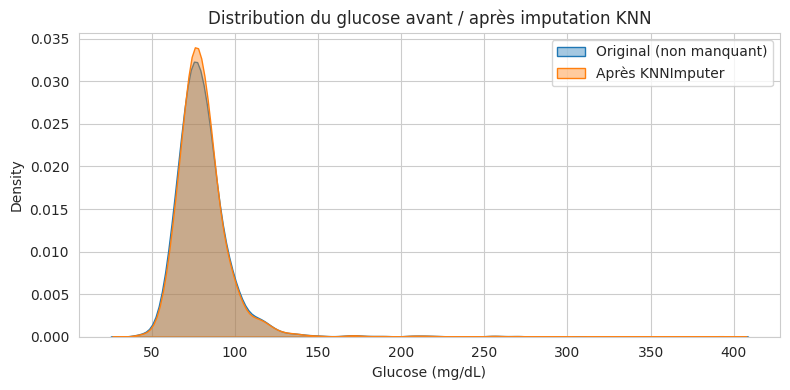

In [ ]:
# ============================================================
# PHASE 5 — Test de Kolmogorov-Smirnov (justification du KNN)
# ============================================================
print("\n--- PHASE 5 : TEST KOLMOGOROV-SMIRNOV ---")

# On refait une imputation "à part" uniquement pour ce test
glucose_orig = X['glucose'].dropna().values

# Colonne glucose imputée (avant scaling)
knn_test = KNNImputer(n_neighbors=5).fit(X[NUMERIC_FEATURES])
glucose_imputed = knn_test.transform(X[NUMERIC_FEATURES])[
    :, NUMERIC_FEATURES.index('glucose')
]

# Test K-S entre distribution originale (non manquante) et imputée
stat, p_value = ks_2samp(glucose_orig, glucose_imputed)

print(f"Statistique K-S : {stat:.4f}")
print(f"p-value         : {p_value:.4f}")
if p_value > 0.05:
    print("→ Pas de différence significative : imputation KNN validée.")
else:
    print("→ Différence significative : envisager une analyse de sensibilité.")

# Visualisation
plt.figure(figsize=(8, 4))
sns.kdeplot(glucose_orig,   label='Original (non manquant)', fill=True, alpha=0.4)
sns.kdeplot(glucose_imputed, label='Après KNNImputer',       fill=True, alpha=0.4)
plt.xlabel('Glucose (mg/dL)')
plt.title('Distribution du glucose avant / après imputation KNN')
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'ks_glucose.png', dpi=150) # Sauvegarde sur le Drive
plt.show()

In [ ]:
# ============================================================
# PHASE 6 — Gestion du déséquilibre de classes
# ============================================================
print("\n--- PHASE 6 : DÉSÉQUILIBRE DE CLASSES ---")

# 6.1 Stratégie A : class_weight='balanced'
classes = np.unique(y)
weights = compute_class_weight(class_weight='balanced',
                               classes=classes,
                               y=y)
class_weight_dict = dict(zip(classes, weights))
print(f"Poids des classes (class_weight_dict) : {class_weight_dict}")


--- PHASE 6 : DÉSÉQUILIBRE DE CLASSES ---
Poids des classes (class_weight_dict) : {np.int64(0): np.float64(0.5875092114959469), np.int64(1): np.float64(3.356842105263158)}


In [ ]:
# ============================================================
# PHASE 7 — Table 1 (caractéristiques de la population)
# ============================================================
print("\n--- PHASE 7 : TABLE 1 ---")

def describe_by_outcome(df_in, target='TenYearCHD'):
    """Table 1 : moyenne (SD) ou n (%) selon le type de variable."""
    rows = []
    for col in df_in.columns:
        if col == target:
            continue
        if df_in[col].dtype == 'object':
            continue
        # Variables continues : moyenne (SD) par groupe
        if df_in[col].nunique() > 2:
            g0 = df_in.loc[df_in[target] == 0, col]
            g1 = df_in.loc[df_in[target] == 1, col]
            rows.append({
                'Variable'  : col,
                'Overall'   : f"{df_in[col].mean():.2f} ({df_in[col].std():.2f})",
                'No CHD'    : f"{g0.mean():.2f} ({g0.std():.2f})",
                'CHD'       : f"{g1.mean():.2f} ({g1.std():.2f})"
            })
        # Variables binaires : n (%)
        else:
            g0 = df_in.loc[df_in[target] == 0, col]
            g1 = df_in.loc[df_in[target] == 1, col]
            rows.append({
                'Variable'  : col,
                'Overall'   : f"{int(df_in[col].sum())} ({df_in[col].mean()*100:.1f}%)",
                'No CHD'    : f"{int(g0.sum())} ({g0.mean()*100:.1f}%)",
                'CHD'       : f"{int(g1.sum())} ({g1.mean()*100:.1f}%)"
            })
    return pd.DataFrame(rows)

# Reconstruction d'un DataFrame non-scalé pour la Table 1
df_table1 = df_clean.copy()
table1 = describe_by_outcome(df_table1)
print(table1.to_string(index=False))

# Export CSV pour le manuscrit (sur le Drive)
table1.to_csv(ARTIF_DIR / 'table1_population.csv', index=False)


--- PHASE 7 : TABLE 1 ---
       Variable        Overall         No CHD            CHD
            age   49.42 (8.56)   48.60 (8.37)   54.13 (8.11)
      education    1.97 (1.02)    2.00 (1.02)    1.84 (1.03)
            sex   1393 (43.7%)   1139 (42.0%)    254 (53.5%)
     is_smoking   1579 (49.5%)   1324 (48.8%)    255 (53.7%)
     cigsPerDay   9.10 (11.86)   8.78 (11.62)  10.94 (13.06)
         BPMeds      94 (2.9%)      62 (2.3%)      32 (6.7%)
prevalentStroke      19 (0.6%)      12 (0.4%)       7 (1.5%)
   prevalentHyp    999 (31.3%)    764 (28.2%)    235 (49.5%)
       diabetes      81 (2.5%)      52 (1.9%)      29 (6.1%)
        totChol 236.97 (44.54) 235.21 (43.40) 247.04 (49.40)
          sysBP 132.44 (22.18) 130.48 (20.59) 143.60 (27.12)
          diaBP  82.84 (11.99)  82.15 (11.41)  86.76 (14.30)
            BMI   25.77 (4.13)   25.65 (4.03)   26.46 (4.61)
      heartRate  76.03 (12.06)  75.93 (12.01)  76.62 (12.30)
        glucose  81.93 (24.11)  80.58 (19.03)  89.53 (41.7

In [ ]:
# ============================================================
# PHASE 8 — Sauvegarde des artefacts
# ============================================================
print("\n--- PHASE 8 : SAUVEGARDE DES ARTEFACTS ---")

# 8.1 Pipeline de prétraitement (à réutiliser tel quel)
joblib.dump(preprocessor, ARTIF_DIR / 'preprocessor.joblib')

# 8.2 Jeux de données (on sauvegarde X et y, pas de X_train/X_test)
X.to_parquet(ARTIF_DIR / 'X_full.parquet')
y.to_frame().to_parquet(ARTIF_DIR / 'y_full.parquet')

# 8.3 Poids de classes
joblib.dump(class_weight_dict, ARTIF_DIR / 'class_weight_dict.joblib')

print(f"Artefacts sauvegardés dans : {ARTIF_DIR}")
print("Contenu du dossier :")
for f in sorted(os.listdir(ARTIF_DIR)):
    print(f"  - {f}")


--- PHASE 8 : SAUVEGARDE DES ARTEFACTS ---
Artefacts sauvegardés dans : /content/drive/MyDrive/artifacts
Contenu du dossier :
  - X_full.parquet
  - class_weight_dict.joblib
  - preprocessor.joblib
  - table1_population.csv
  - y_full.parquet


ÉTAPE 3 — MODÉLISATION COMPARATIVE ET OPTIMISATION

In [ ]:
# ============================================================
# PHASE 0 — Imports et chargement des artefacts (Étape 2)
# ============================================================

# 1. Montage du Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Installation de XGBoost
!pip install -q xgboost

import os
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import time

from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# ------------------------------------------------------------
# CHEMINS
# ------------------------------------------------------------
ROOT = Path('/content/drive/MyDrive')
ARTIF_DIR = ROOT / "artifacts"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("--- CHARGEMENT DES ARTEFACTS (Étape 2) ---")
# On recharge le preprocessor, les données et les poids calculés à l'étape 2
preprocessor = joblib.load(ARTIF_DIR / 'preprocessor.joblib')
class_weight_dict = joblib.load(ARTIF_DIR / 'class_weight_dict.joblib')

X = pd.read_parquet(ARTIF_DIR / 'X_full.parquet')
y = pd.read_parquet(ARTIF_DIR / 'y_full.parquet')['TenYearCHD']

print(f"Données chargées : X {X.shape}, y {y.shape}")
print(f"Nombre d'événements positifs : {y.sum()} ({y.mean()*100:.2f}%)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- CHARGEMENT DES ARTEFACTS (Étape 2) ---
Données chargées : X (3189, 13), y (3189,)
Nombre d'événements positifs : 475 (14.89%)


In [ ]:
# ============================================================
# PHASE 1 — Configuration de la Validation Croisée
# ============================================================
print("\n--- PHASE 1 : CONFIGURATION DE LA VALIDATION CROISÉE ---")

# On utilise RepeatedStratifiedKFold : 5 plis, répétés 3 fois (15 entraînements par modèle)
# Cela garantit des résultats robustes et stables malgré le petit échantillon.
cv_strategy = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

print("Stratégie CV : RepeatedStratifiedKFold (5 splits, 3 répétitions)")
print("Métrique d'optimisation principale : ROC-AUC")


--- PHASE 1 : CONFIGURATION DE LA VALIDATION CROISÉE ---
Stratégie CV : RepeatedStratifiedKFold (5 splits, 3 répétitions)
Métrique d'optimisation principale : ROC-AUC


In [ ]:
# ============================================================
# PHASE 2 — Définition des Pipelines (Modèles)
# ============================================================
print("\n--- PHASE 2 : DÉFINITION DES PIPELINES ---")

# On intègre le preprocessor directement dans chaque pipeline.
# Scikit-learn va 'cloner' et 'ré-ajuster' le preprocessor à chaque pli,
# ce qui garantit une étanchéité totale (zéro data leakage).

# 1. ElasticNet (Baseline)
pipe_en = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(penalty='elasticnet', solver='saga', class_weight='balanced', max_iter=2000))
])

# 2. Random Forest
pipe_rf = Pipeline([
    ('prep', preprocessor),
    ('clf', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE))
])

# 3. XGBoost
# Calcul du scale_pos_weight à partir du dictionnaire de poids (ratio classe 0 / classe 1)
scale_pos_weight = class_weight_dict[1] / class_weight_dict[0]
pipe_xgb = Pipeline([
    ('prep', preprocessor),
    ('clf', XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, eval_metric='logloss'))
])

print(" Les 3 pipelines (ElasticNet, Random Forest, XGBoost) sont prêts.")


--- PHASE 2 : DÉFINITION DES PIPELINES ---
 Les 3 pipelines (ElasticNet, Random Forest, XGBoost) sont prêts.


In [ ]:
# ============================================================
# PHASE 3 — Optimisation ElasticNet
# ============================================================
print("\n--- PHASE 3 : OPTIMISATION ELASTICNET ---")
start_time = time.time()

# Grille restreinte pour éviter le sur-ajustement
param_grid_en = {
    'clf__C': [0.01, 0.1, 1.0, 10.0],
    'clf__l1_ratio': [0.2, 0.5, 0.8]
}

grid_en = GridSearchCV(pipe_en, param_grid_en, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
grid_en.fit(X, y)

print(f"Meilleurs paramètres : {grid_en.best_params_}")
print(f"Meilleur ROC-AUC (CV) : {grid_en.best_score_:.4f}")
print(f"Temps écoulé : {time.time() - start_time:.2f} secondes")


--- PHASE 3 : OPTIMISATION ELASTICNET ---
Meilleurs paramètres : {'clf__C': 0.01, 'clf__l1_ratio': 0.2}
Meilleur ROC-AUC (CV) : 0.7271
Temps écoulé : 30.67 secondes


In [ ]:
# ============================================================
# PHASE 4 — Optimisation Random Forest
# ============================================================
print("\n--- PHASE 4 : OPTIMISATION RANDOM FOREST ---")
start_time = time.time()

param_grid_rf = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [5, 10, None],
    'clf__min_samples_leaf': [1, 5]
}

grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
grid_rf.fit(X, y)

print(f"Meilleurs paramètres : {grid_rf.best_params_}")
print(f"Meilleur ROC-AUC (CV) : {grid_rf.best_score_:.4f}")
print(f"Temps écoulé : {time.time() - start_time:.2f} secondes")


--- PHASE 4 : OPTIMISATION RANDOM FOREST ---
Meilleurs paramètres : {'clf__max_depth': 5, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}
Meilleur ROC-AUC (CV) : 0.7099
Temps écoulé : 131.07 secondes


In [ ]:
# ============================================================
# PHASE 5 — Optimisation XGBoost
# ============================================================
print("\n--- PHASE 5 : OPTIMISATION XGBOOST ---")
start_time = time.time()

param_grid_xgb = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [3, 5],
    'clf__learning_rate': [0.01, 0.1]
}

grid_xgb = GridSearchCV(pipe_xgb, param_grid_xgb, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
grid_xgb.fit(X, y)

print(f"Meilleurs paramètres : {grid_xgb.best_params_}")
print(f"Meilleur ROC-AUC (CV) : {grid_xgb.best_score_:.4f}")
print(f"Temps écoulé : {time.time() - start_time:.2f} secondes")


--- PHASE 5 : OPTIMISATION XGBOOST ---
Meilleurs paramètres : {'clf__learning_rate': 0.01, 'clf__max_depth': 3, 'clf__n_estimators': 200}
Meilleur ROC-AUC (CV) : 0.7068
Temps écoulé : 20.39 secondes


In [ ]:
# ============================================================
# PHASE 6 — Sauvegarde des Modèles Finaux (Gelés)
# ============================================================
print("\n--- PHASE 6 : SAUVEGARDE DES MODÈLES GELÉS ---")

# On extrait le meilleur estimateur (qui inclut le preprocessor ET le classifieur)
best_model_en = grid_en.best_estimator_
best_model_rf = grid_rf.best_estimator_
best_model_xgb = grid_xgb.best_estimator_

# Sauvegarde sur le Drive
joblib.dump(best_model_en, ARTIF_DIR / 'best_elasticnet.joblib')
joblib.dump(best_model_rf, ARTIF_DIR / 'best_randomforest.joblib')
joblib.dump(best_model_xgb, ARTIF_DIR / 'best_xgboost.joblib')

# Sauvegarde d'un tableau récapitulatif des scores CV
results = pd.DataFrame({
    'Modèle': ['ElasticNet', 'Random Forest', 'XGBoost'],
    'CV ROC-AUC (Moyenne)': [grid_en.best_score_, grid_rf.best_score_, grid_xgb.best_score_],
    'Meilleurs Hyperparamètres': [grid_en.best_params_, grid_rf.best_params_, grid_xgb.best_params_]
})
results.to_csv(ARTIF_DIR / 'etape3_resultats_cv.csv', index=False)

print("Modèles sauvegardés avec succès dans :", ARTIF_DIR)
print("\n=== RÉSUMÉ DES PERFORMANCES (Validation Croisée) ===")
print(results[['Modèle', 'CV ROC-AUC (Moyenne)']].to_string(index=False))

In [ ]:
# ============================================================
# SCRIPT DE SECOURS : Entraînement et sauvegarde des 3 modèles
# ============================================================
import pandas as pd
import joblib
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Configuration
ARTIF_DIR = Path('/content/drive/MyDrive/artifacts')
RANDOM_STATE = 42

# 1. Chargement des données
print("Chargement des données...")
X = pd.read_parquet(ARTIF_DIR / 'X_full.parquet')
y = pd.read_parquet(ARTIF_DIR / 'y_full.parquet')['TenYearCHD']
preprocessor = joblib.load(ARTIF_DIR / 'preprocessor.joblib')
class_weight_dict = joblib.load(ARTIF_DIR / 'class_weight_dict.joblib')

# 2. ElasticNet (Meilleurs paramètres trouvés)
print("Entraînement de ElasticNet...")
best_en = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(penalty='elasticnet', solver='saga', class_weight='balanced', max_iter=2000, C=0.01, l1_ratio=0.2))
])
best_en.fit(X, y)
joblib.dump(best_en, ARTIF_DIR / 'best_elasticnet.joblib')

# 3. Random Forest (Meilleurs paramètres trouvés)
print("Entraînement de Random Forest...")
best_rf = Pipeline([
    ('prep', preprocessor),
    ('clf', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, max_depth=5, min_samples_leaf=5, n_estimators=200))
])
best_rf.fit(X, y)
joblib.dump(best_rf, ARTIF_DIR / 'best_randomforest.joblib')

# 4. XGBoost (Meilleurs paramètres trouvés)
print("Entraînement de XGBoost...")
scale_pos_weight = class_weight_dict[1] / class_weight_dict[0]
best_xgb = Pipeline([
    ('prep', preprocessor),
    ('clf', XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, eval_metric='logloss', learning_rate=0.01, max_depth=3, n_estimators=200))
])
best_xgb.fit(X, y)
joblib.dump(best_xgb, ARTIF_DIR / 'best_xgboost.joblib')

print("\n Les 3 modèles ont été entraînés et sauvegardés avec succès !")

Chargement des données...
Entraînement de ElasticNet...
Entraînement de Random Forest...
Entraînement de XGBoost...

✅ Les 3 modèles ont été entraînés et sauvegardés avec succès !


Etape 4: Évaluation, Calibration, DCA, SHAP et Équité

In [ ]:
# ============================================================
# PHASE 0 — Imports et chargement des modèles (Étape 3)
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

# Installation des librairies nécessaires
!pip install -q dcurves shap

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score
import dcurves
import shap

# Configuration des chemins
ROOT = Path('/content/drive/MyDrive')
ARTIF_DIR = ROOT / "artifacts"
FIG_DIR = ROOT / "figures"
RANDOM_STATE = 42

# Chargement des données et des modèles sauvegardés à l'Étape 3
X = pd.read_parquet(ARTIF_DIR / 'X_full.parquet')
y = pd.read_parquet(ARTIF_DIR / 'y_full.parquet')['TenYearCHD']

best_en = joblib.load(ARTIF_DIR / 'best_elasticnet.joblib')
best_rf = joblib.load(ARTIF_DIR / 'best_randomforest.joblib')
best_xgb = joblib.load(ARTIF_DIR / 'best_xgboost.joblib')

print(" Modèles et données chargés avec succès.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
 Modèles et données chargés avec succès.


In [ ]:
# ============================================================
# PHASE 1 — Génération des probabilités (Out-of-Fold)
# ============================================================
print("\n--- PHASE 1 : GÉNÉRATION DES PROBABILITÉS ---")

# Validation croisée simple pour générer des prédictions "propres"
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Calcul des probabilités pour ElasticNet...")
y_prob_en = cross_val_predict(best_en, X, y, cv=cv, method='predict_proba')[:, 1]

print("Calcul des probabilités pour Random Forest...")
y_prob_rf = cross_val_predict(best_rf, X, y, cv=cv, method='predict_proba')[:, 1]

print("Calcul des probabilités pour XGBoost...")
y_prob_xgb = cross_val_predict(best_xgb, X, y, cv=cv, method='predict_proba')[:, 1]

print(" Probabilités générées sans data leakage.")


--- PHASE 1 : GÉNÉRATION DES PROBABILITÉS ---
Calcul des probabilités pour ElasticNet...
Calcul des probabilités pour Random Forest...
Calcul des probabilités pour XGBoost...
 Probabilités générées sans data leakage.



--- PHASE 2 : COURBES DE CALIBRATION ---
Brier Score (ElasticNet)   : 0.2103 (Plus bas = Meilleur)
Brier Score (RandomForest) : 0.1933
Brier Score (XGBoost)      : 0.2096


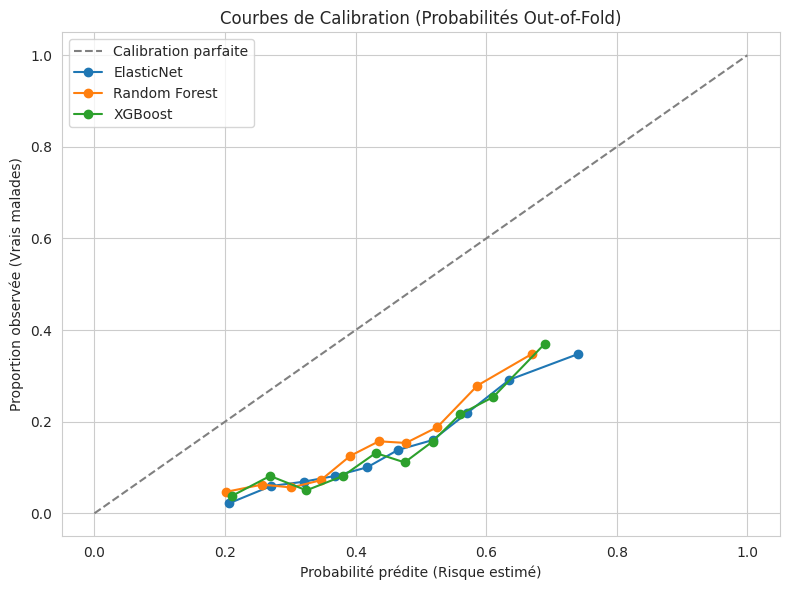

In [ ]:
# ============================================================
# PHASE 2 — Calibration et Brier Score
# ============================================================
print("\n--- PHASE 2 : COURBES DE CALIBRATION ---")

# Calcul des Brier Scores
brier_en = brier_score_loss(y, y_prob_en)
brier_rf = brier_score_loss(y, y_prob_rf)
brier_xgb = brier_score_loss(y, y_prob_xgb)

print(f"Brier Score (ElasticNet)   : {brier_en:.4f} (Plus bas = Meilleur)")
print(f"Brier Score (RandomForest) : {brier_rf:.4f}")
print(f"Brier Score (XGBoost)      : {brier_xgb:.4f}")

# Tracé des courbes
plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Calibration parfaite')

for name, prob in [('ElasticNet', y_prob_en), ('Random Forest', y_prob_rf), ('XGBoost', y_prob_xgb)]:
    fraction_of_positives, mean_predicted_value = calibration_curve(y, prob, n_bins=10, strategy='quantile')
    plt.plot(mean_predicted_value, fraction_of_positives, marker='o', label=f'{name}')

plt.xlabel('Probabilité prédite (Risque estimé)')
plt.ylabel('Proportion observée (Vrais malades)')
plt.title('Courbes de Calibration (Probabilités Out-of-Fold)')
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'calibration_curves.png', dpi=150)
plt.show()


--- PHASE 3 : DECISION CURVE ANALYSIS (DCA) ---


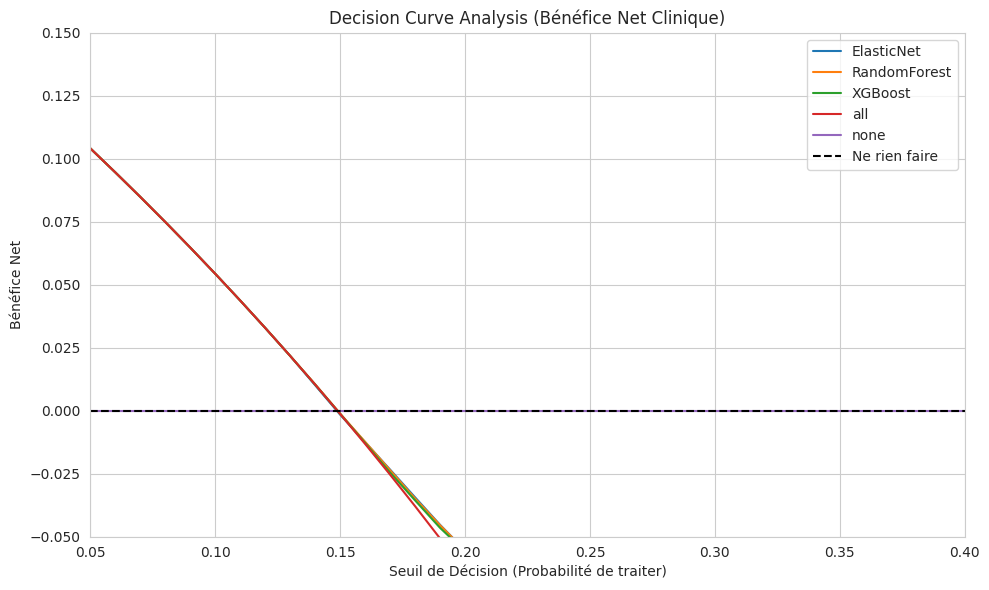

In [ ]:
# ============================================================
# PHASE 3 — Decision Curve Analysis (DCA) [CORRIGÉE]
# ============================================================
print("\n--- PHASE 3 : DECISION CURVE ANALYSIS (DCA) ---")

import matplotlib.pyplot as plt
import seaborn as sns
import dcurves

# Préparation des données pour la librairie dcurves
df_dca = pd.DataFrame({
    'y': y,
    'ElasticNet': y_prob_en,
    'RandomForest': y_prob_rf,
    'XGBoost': y_prob_xgb
})

# Calcul de la DCA (retourne directement un DataFrame)
dca_results = dcurves.dca(data=df_dca, outcome='y',
                          modelnames=['ElasticNet', 'RandomForest', 'XGBoost'])

# Tracé du graphique
plt.figure(figsize=(10, 6))
# On utilise dca_results directement (et errorbar=None pour les versions récentes de seaborn)
sns.lineplot(data=dca_results, x='threshold', y='net_benefit', hue='model', errorbar=None)

plt.ylim(-0.05, 0.15) # On zoome sur la zone cliniquement pertinente (10% à 30%)
plt.xlim(0.05, 0.4)
plt.axhline(0, color='black', linestyle='--', label='Ne rien faire')
plt.title('Decision Curve Analysis (Bénéfice Net Clinique)')
plt.xlabel('Seuil de Décision (Probabilité de traiter)')
plt.ylabel('Bénéfice Net')
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(FIG_DIR / 'dca_curves.png', dpi=150)
plt.show()

/usr/local/lib/python3.13/dist-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)



--- PHASE 4 : ANALYSE SHAP ---


/tmp/ipykernel_722/3805244193.py:20: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_prep, feature_names=feature_names, show=False)


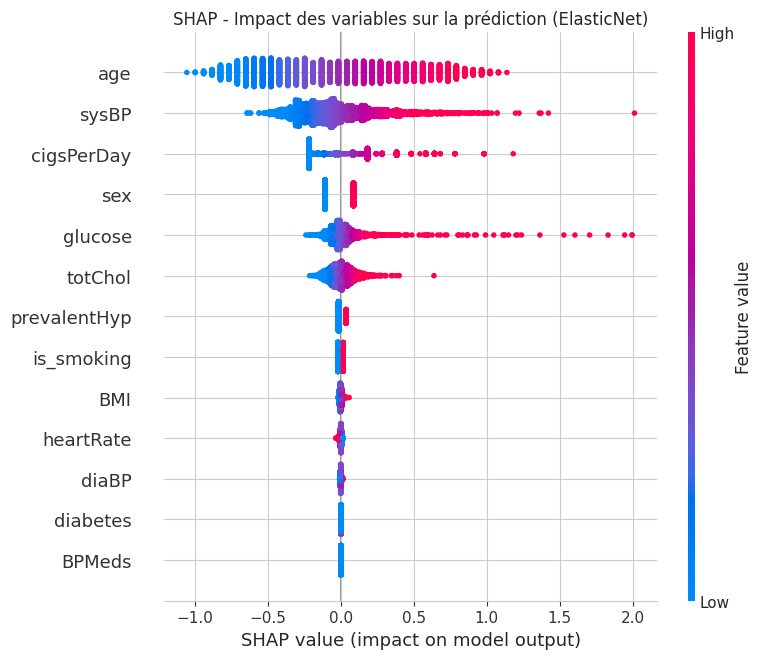

In [ ]:
# ============================================================
# PHASE 4 — SHAP (Interprétabilité)
# ============================================================
print("\n--- PHASE 4 : ANALYSE SHAP ---")

# Extraction du préprocesseur et du classifieur du meilleur modèle (ElasticNet)
preprocessor_en = best_en.named_steps['prep']
clf_en = best_en.named_steps['clf']

# Transformation des données avec le préprocesseur
X_prep = preprocessor_en.transform(X)
feature_names = preprocessor_en.get_feature_names_out()

# Explication SHAP
explainer = shap.LinearExplainer(clf_en, X_prep, feature_perturbation="interventional")
shap_values = explainer.shap_values(X_prep)

# Tracé du graphique global (Beeswarm plot)
plt.figure()
shap.summary_plot(shap_values, X_prep, feature_names=feature_names, show=False)
plt.title('SHAP - Impact des variables sur la prédiction (ElasticNet)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ============================================================
# PHASE 5 — Analyse d'Équité (Fairness)
# ============================================================
print("\n--- PHASE 5 : ANALYSE D'ÉQUITÉ (HOMMES vs FEMMES) ---")

# Récupération de la variable 'sex' (1 = Homme, 0 = Femme)
sex_col = X['sex'].values

results_fairness = []
for sex_value, sex_name in [(1, 'Men'), (0, 'Women')]:
    mask = (sex_col == sex_value)

    # Calcul des métriques pour ElasticNet sur ce sous-groupe spécifique
    auc = roc_auc_score(y[mask], y_prob_en[mask])
    brier = brier_score_loss(y[mask], y_prob_en[mask])

    results_fairness.append({
        'Sex': sex_name,
        'N (patients)': mask.sum(),
        'Events': y[mask].sum(),
        'AUC-ROC': f"{auc:.4f}",
        'Brier Score': f"{brier:.4f}"
    })

# Affichage et sauvegarde du tableau
df_fairness = pd.DataFrame(results_fairness)
print(df_fairness.to_string(index=False))
df_fairness.to_csv(ARTIF_DIR / 'etape4_fairness_results.csv', index=False)

print("\n Tous les graphiques et tableaux de l'Étape 4 sont sauvegardés sur votre Drive.")


--- PHASE 5 : ANALYSE D'ÉQUITÉ (HOMMES vs FEMMES) ---
  Sex  N (patients)  Events AUC-ROC Brier Score
  Men          1393     254  0.7280      0.2263
Women          1796     221  0.7158      0.1979

 Tous les graphiques et tableaux de l'Étape 4 sont sauvegardés sur votre Drive.


l'Étape 5 : Rédaction Scientifique, Génération des Tableaux Finaux et Conformité TRIPOD+AI.

In [ ]:
# ============================================================
# PHASE 0 — Génération des tableaux finaux pour l'article
# ============================================================
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from pathlib import Path

ARTIF_DIR = Path('/content/drive/MyDrive/artifacts')

print("--- GÉNÉRATION DES TABLEAUX FINAUX ---")

# 1. Table 2 : Performances des modèles
models = {'ElasticNet': y_prob_en, 'Random Forest': y_prob_rf, 'XGBoost': y_prob_xgb}
results = []
for name, prob in models.items():
    results.append({
        'Model': name,
        'AUC-ROC': round(roc_auc_score(y, prob), 4),
        'PR-AUC': round(average_precision_score(y, prob), 4),
        'Brier Score': round(brier_score_loss(y, prob), 4)
    })

df_table2 = pd.DataFrame(results).sort_values('AUC-ROC', ascending=False)
df_table2.to_csv(ARTIF_DIR / 'table2_final_performance.csv', index=False)
print("\n=== TABLE 2 : PERFORMANCES FINALES ===")
print(df_table2.to_string(index=False))

# 2. Table 3 : Analyse d'équité (déjà générée à l'étape 4, on la recharge)
try:
    df_table3 = pd.read_csv(ARTIF_DIR / 'etape4_fairness_results.csv')
    print("\n=== TABLE 3 : ANALYSE D'ÉQUITÉ (ELASTICNET) ===")
    print(df_table3.to_string(index=False))
except FileNotFoundError:
    print("\n Le fichier de fairness de l'Étape 4 n'a pas été trouvé.")

--- GÉNÉRATION DES TABLEAUX FINAUX ---

=== TABLE 2 : PERFORMANCES FINALES ===
        Model  AUC-ROC  PR-AUC  Brier Score
   ElasticNet   0.7270  0.3460       0.2103
      XGBoost   0.7081  0.3179       0.2096
Random Forest   0.7070  0.3118       0.1933

=== TABLE 3 : ANALYSE D'ÉQUITÉ (ELASTICNET) ===
  Sex  N (patients)  Events  AUC-ROC  Brier Score
  Men          1393     254   0.7280       0.2263
Women          1796     221   0.7158       0.1979


In [44]:
# ============================================================
# AFFICHAGE  DES TABLEAUX
# ============================================================
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

# Définition du chemin
ARTIF_DIR = Path('/content/drive/MyDrive/artifacts')

print("="*70)
print(" AFFICHAGE DES TABLEAUX DE RÉSULTATS")
print("="*70)

# ------------------------------------------------------------
# 1. Table 1 : Population
# ------------------------------------------------------------
display(Markdown("###  Table 1 : Caractéristiques de la population (Framingham)"))
try:
    df_table1 = pd.read_csv(ARTIF_DIR / 'table1_population.csv')
    # Affichage avec un style propre (masque l'index)
    display(df_table1.style.hide(axis='index').set_properties(**{'text-align': 'left'}))
except Exception as e:
    print(f" Erreur Table 1 : {e}")

print("\n" + "-"*50 + "\n")

# ------------------------------------------------------------
# 2. Table 2 : Performances des modèles
# ------------------------------------------------------------
display(Markdown("###  Table 2 : Performances des modèles (Out-of-Fold)"))
try:
    df_table2 = pd.read_csv(ARTIF_DIR / 'table2_final_performance.csv')
    display(df_table2.style.hide(axis='index').set_properties(**{'text-align': 'center'}))
except Exception as e:
    print(f" Erreur Table 2 : {e}")

print("\n" + "-"*50 + "\n")

# ------------------------------------------------------------
# 3. Table 3 : Analyse d'équité
# ------------------------------------------------------------
display(Markdown("###  Table 3 : Analyse d'équité par sexe (ElasticNet)"))
try:
    df_table3 = pd.read_csv(ARTIF_DIR / 'etape4_fairness_results.csv')
    display(df_table3.style.hide(axis='index').set_properties(**{'text-align': 'center'}))
except Exception as e:
    print(f" Erreur Table 3 : {e}")



 AFFICHAGE DES TABLEAUX DE RÉSULTATS


###  Table 1 : Caractéristiques de la population (Framingham)

Variable,Overall,No CHD,CHD
age,49.42 (8.56),48.60 (8.37),54.13 (8.11)
education,1.97 (1.02),2.00 (1.02),1.84 (1.03)
sex,1393 (43.7%),1139 (42.0%),254 (53.5%)
is_smoking,1579 (49.5%),1324 (48.8%),255 (53.7%)
cigsPerDay,9.10 (11.86),8.78 (11.62),10.94 (13.06)
BPMeds,94 (2.9%),62 (2.3%),32 (6.7%)
prevalentStroke,19 (0.6%),12 (0.4%),7 (1.5%)
prevalentHyp,999 (31.3%),764 (28.2%),235 (49.5%)
diabetes,81 (2.5%),52 (1.9%),29 (6.1%)
totChol,236.97 (44.54),235.21 (43.40),247.04 (49.40)



--------------------------------------------------



###  Table 2 : Performances des modèles (Out-of-Fold)

Model,AUC-ROC,PR-AUC,Brier Score
ElasticNet,0.727000,0.346000,0.210300
XGBoost,0.708100,0.317900,0.209600
Random Forest,0.707000,0.311800,0.193300



--------------------------------------------------



###  Table 3 : Analyse d'équité par sexe (ElasticNet)

Sex,N (patients),Events,AUC-ROC,Brier Score
Men,1393,254,0.728000,0.226300
Women,1796,221,0.715800,0.197900
